# Unidad 31. Visualización con propósito: figuras, ejes y primeras líneas

**Bloque:** Matplotlib (UT3) · **Tiempo orientativo:** 5–7 horas

Visualizar no consiste en decorar números: consiste en seleccionar una representación que ayude a responder una pregunta concreta. En esta unidad crearás gráficos de líneas sencillos, pero sobre todo aprenderás a identificar sus elementos, etiquetarlos y comprobar que comunican lo que crees que comunican.

**Necesitas:** Python, listas, funciones básicas, arrays de NumPy y la lectura elemental de un `DataFrame` de Pandas. No necesitas conocimientos de modelos de aprendizaje automático.

## Resultados de aprendizaje

Al terminar podrás:

- distinguir datos, figura (`Figure`) y ejes (`Axes`);
- crear una figura mediante la interfaz recomendada `fig, ax = plt.subplots()`;
- representar una serie ordenada con `ax.plot()`;
- añadir título, etiquetas con unidades, leyenda y cuadrícula cuando aporten contexto;
- detectar gráficos que no permiten responder la pregunta planteada.

**Idea clave.** Un gráfico no prueba una explicación causal. Muestra valores y patrones; para explicar sus causas hacen falta datos, diseño de estudio y evidencia adicional.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

print(f"Matplotlib: {plt.matplotlib.__version__}")

Matplotlib: 3.11.2


## 1. Antes de escribir código: pregunta, datos y gráfico

Formula primero una pregunta verificable. Por ejemplo: **«¿Cómo cambió la temperatura durante el turno?»**. Si cada observación tiene una posición natural y ordenada —hora, fecha, iteración o distancia—, una línea suele ayudar a leer la evolución.

No uses una línea para categorías sin orden significativo, como nombres de departamentos. Unirlas sugiere una continuidad que no existe; más adelante emplearemos barras para ese caso.

Para que un gráfico pueda revisarse, debe indicar qué mide cada eje y, cuando corresponda, sus unidades. Un título explica la pregunta o el contexto, no solo el tipo de gráfico.

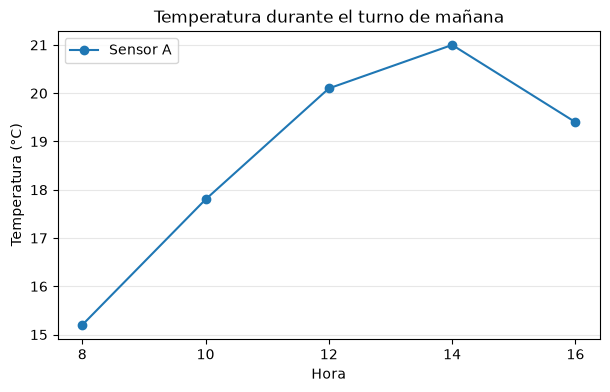

In [2]:
horas = np.array([8, 10, 12, 14, 16])
temperatura_c = np.array([15.2, 17.8, 20.1, 21.0, 19.4])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(horas, temperatura_c, marker="o", label="Sensor A")
ax.set_title("Temperatura durante el turno de mañana")
ax.set_xlabel("Hora")
ax.set_ylabel("Temperatura (°C)")
ax.set_xticks(horas)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.show()

## 2. Figura y ejes: dos objetos distintos

- La **figura** (`fig`) es el lienzo completo: puede contener uno o varios gráficos.
- Unos **ejes** (`ax`) son una zona concreta de la figura donde se dibujan los datos, las escalas, las etiquetas y la leyenda.

La interfaz `fig, ax = plt.subplots()` hace visible esta relación y funciona igual cuando, más adelante, una figura tenga varios ejes. Por eso será nuestra forma habitual de crear gráficos.

`ax.plot(x, y)` conecta los pares `(x, y)` en el orden recibido. Antes de interpretarlo, comprueba que `x` está ordenado y que ambos arrays tienen la misma longitud.

Figure contiene 1 eje(s).
Axes tiene 1 línea dibujada.


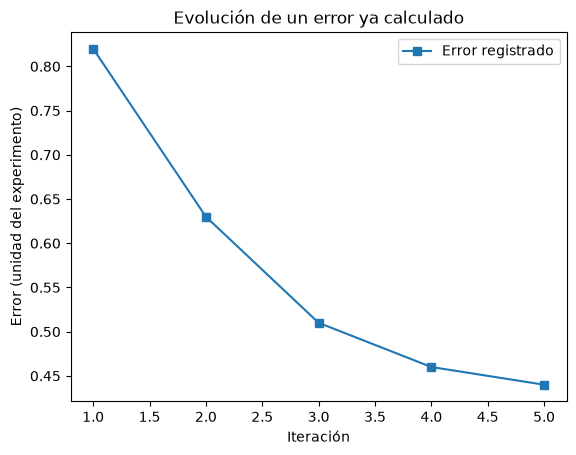

In [3]:
iteraciones = np.arange(1, 6)
error = np.array([0.82, 0.63, 0.51, 0.46, 0.44])

fig, ax = plt.subplots()
linea = ax.plot(iteraciones, error, color="tab:blue", marker="s", label="Error registrado")
ax.set(
    title="Evolución de un error ya calculado",
    xlabel="Iteración",
    ylabel="Error (unidad del experimento)",
)
ax.legend()

print(type(fig).__name__, "contiene", len(fig.axes), "eje(s).")
print(type(ax).__name__, "tiene", len(linea), "línea dibujada.")
plt.show()

## 3. Una línea puede comparar varias series

Si las series comparten la misma variable horizontal y la misma unidad vertical, puedes dibujarlas sobre el mismo eje. Dales etiquetas diferentes y añade una leyenda. No compares en el mismo eje magnitudes con escalas o unidades incompatibles: esa decisión puede ocultar información importante.

Los argumentos `color`, `linestyle` y `marker` mejoran la distinción visual, pero el color no debe ser el único modo de distinguir una serie. La leyenda y los marcadores también ayudan a quien imprima el gráfico o no distinga ciertos colores.

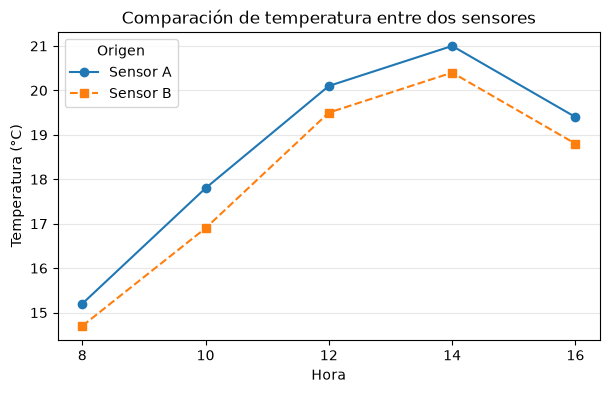

In [4]:
horas = np.array([8, 10, 12, 14, 16])
sensor_a = np.array([15.2, 17.8, 20.1, 21.0, 19.4])
sensor_b = np.array([14.7, 16.9, 19.5, 20.4, 18.8])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(horas, sensor_a, marker="o", label="Sensor A")
ax.plot(horas, sensor_b, marker="s", linestyle="--", label="Sensor B")
ax.set_title("Comparación de temperatura entre dos sensores")
ax.set_xlabel("Hora")
ax.set_ylabel("Temperatura (°C)")
ax.set_xticks(horas)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Origen")
plt.show()

## 4. Lectura crítica antes de concluir

En el ejemplo anterior, el sensor A da lecturas mayores que B en todas las horas mostradas. Eso **no demuestra** que A sea más exacto ni que B esté mal calibrado: faltan una referencia y más observaciones. Una conclusión responsable describe el patrón visible y separa lo observado de lo que sería necesario investigar.

Revisa siempre esta lista:

1. ¿El tipo de gráfico responde a la pregunta?
2. ¿Las longitudes y el orden de los datos son correctos?
3. ¿Título, ejes y unidades permiten interpretar el gráfico fuera del cuaderno?
4. ¿La leyenda aporta información y no depende solo del color?
5. ¿La conclusión afirma únicamente lo que muestran los datos?

## Práctica guiada

Las columnas de un `DataFrame` pueden entregarse directamente a Matplotlib. El siguiente ejemplo usa datos locales creados en la celda para practicar el puente entre Pandas y Matplotlib.

1. Ejecuta la celda y observa el mínimo y el máximo.
2. Cambia el título para convertirlo en una pregunta concreta.
3. Sustituye el marcador por otro y comprueba que la leyenda sigue siendo necesaria.
4. Escribe una frase que describa el patrón sin explicar su causa.

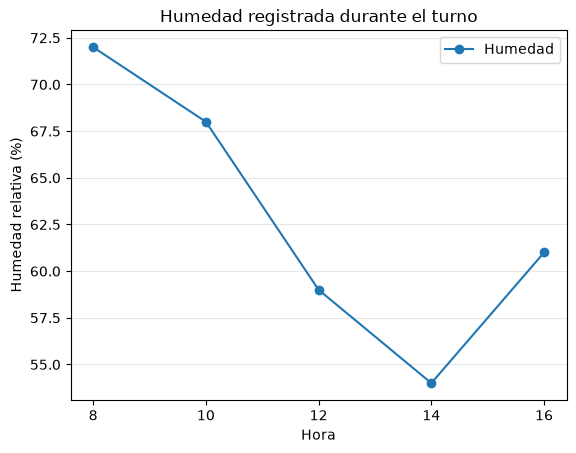

Mínimo: 54 %
Máximo: 72 %


In [5]:
import pandas as pd

lecturas = pd.DataFrame(
    {
        "hora": [8, 10, 12, 14, 16],
        "humedad_pct": [72, 68, 59, 54, 61],
    }
)

fig, ax = plt.subplots()
ax.plot(lecturas["hora"], lecturas["humedad_pct"], marker="o", label="Humedad")
ax.set_title("Humedad registrada durante el turno")
ax.set_xlabel("Hora")
ax.set_ylabel("Humedad relativa (%)")
ax.set_xticks(lecturas["hora"])
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.show()

print("Mínimo:", lecturas["humedad_pct"].min(), "%")
print("Máximo:", lecturas["humedad_pct"].max(), "%")

## Ejercicios

Trabaja en las celdas siguientes. Antes de programar, escribe en un comentario qué pregunta responderá la figura. Puedes consultar la solución cuando hayas intentado cada reto.

### Ejercicio 31.01 · Línea clara

Con `minutos = [0, 15, 30, 45, 60]` y `energia_wh = [4, 9, 15, 18, 20]`, crea una figura con un eje y una línea con marcadores. Incluye un título que indique la evolución, etiquetas con unidades, marcas de x en los minutos y cuadrícula horizontal.

# Pregunta: ¿Conforme pasan los minutos el consumo de energía aumenta?

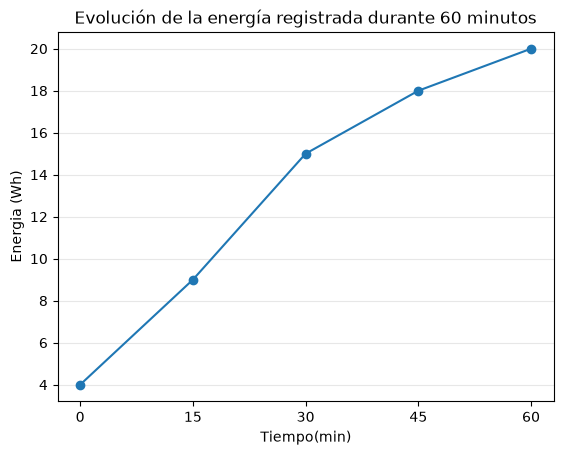

In [24]:
# Escribe aquí tu solución del ejercicio 31.01.
minutos = [0, 15, 30, 45, 60]
energia_wh = [4, 9, 15, 18, 20]

fig, ax = plt.subplots() # Esto genera un lienzo vacio.
ax.plot(minutos, energia_wh, marker = "o") # dibuja la línea uniendo los puntos y añade un marcador circular ("o") en cada lectura.
ax.set_title("Evolución de la energía registrada durante 60 minutos")
ax.set_xlabel("Tiempo(min)")
ax.set_ylabel("Energia (Wh)")
ax.set_xticks(minutos) # fuerza que las marcas del eje horizontal caigan exactamente en [0, 15, 30, 45, 60]
ax.grid(axis="y", alpha = 0.3)
plt.show()

### Ejercicio 31.02 · Dos series comparables

Dos equipos registran la misma magnitud en los mismos instantes:

```python
pasos = np.array([1, 2, 3, 4, 5])
equipo_azul = np.array([9, 14, 18, 21, 23])
equipo_verde = np.array([8, 13, 17, 20, 22])
```

Representa ambas series en el mismo eje. Diferéncialas con marcador y estilo de línea, añade una leyenda y escribe debajo una conclusión limitada a lo que muestran los cinco pasos.

# Pregunta: ¿Cómo evoluciona la magnitud de ambos equipos en los 5 pasos y mantiene el equipo azul la ventaja de 1 unidad?

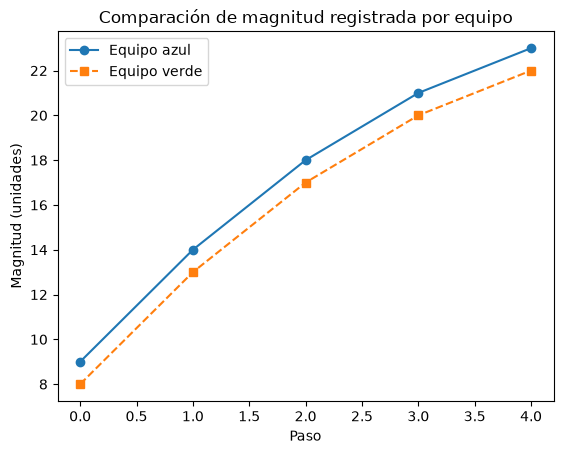

In [ ]:
# Escribe aquí tu solución del ejercicio 31.02.
pasos = np.array([1, 2, 3, 4, 5])
equipo_azul = np.array([9, 14, 18, 21, 23])
equipo_verde = np.array([8, 13, 17, 20, 22])

fig, ax = plt.subplots()
ax.plot(equipo_azul, marker = "o", label = "Equipo azul")
ax.plot(equipo_verde, marker = "s", linestyle = "--", label = "Equipo verde")

ax.set_title("Comparación de magnitud registrada por equipo")
ax.set_xlabel("Paso")
ax.set_ylabel("Magnitud (unidades)")
ax.legend()
plt.show()

# Conclusión: En los cinco pasos observados, ambos equipos crecen de forma paralela
# y el equipo azul se mantiene exactamente 1 unidad por encima del verde en cada paso,
# aunque estos datos no permiten confirmar si ocurre lo mismo fuera de este intervalo ni su causa.

### Ejercicio 31.03 · Diagnóstico de una figura

Este código crea un gráfico difícil de interpretar:

```python
fig, ax = plt.subplots()
ax.plot([3, 1, 2], [18, 12, 15])
plt.show()
```

Reescríbelo para representar temperatura (°C) frente a hora (`[1, 2, 3]`). Incluye las etiquetas y explica en un comentario por qué el orden horizontal importa al conectar puntos con una línea.

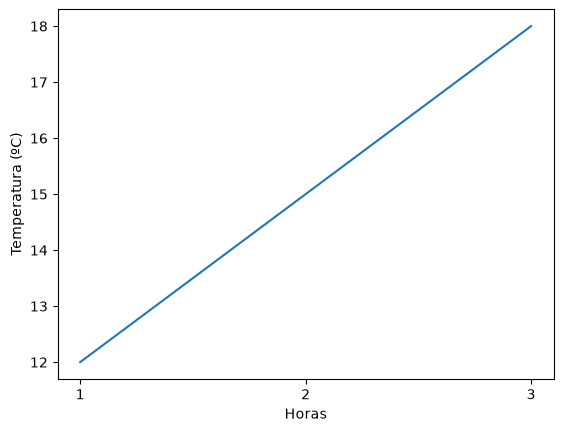

In [69]:
# Escribe aquí tu solución del ejercicio 31.03.
horas = [1, 2, 3]
temperatura = [12, 15, 18]

fig, ax = plt.subplots()
ax.plot(horas, temperatura)
ax.set_xlabel("Horas")
ax.set_ylabel("Temperatura (ºC)")
ax.set_xticks(horas)
plt.show()



### Ejercicio 31.04 · Función reutilizable

Define `grafico_serie(x, y, titulo, etiqueta_y)` que cree y devuelva `fig, ax`. La función debe usar `ax.plot`, etiquetas de eje, título y cuadrícula horizontal. Compruébala con una serie de al menos cuatro valores y verifica con `len(fig.axes)` que contiene un eje.

Número de ejes en la figura: 1


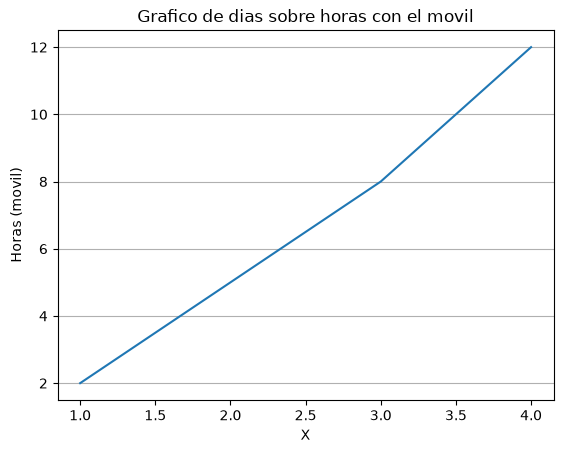

In [75]:
# Escribe aquí tu solución del ejercicio 31.04.
def grafico_serie(x,y,titulo,etiqueta_y):
    fig, ax = plt.subplots()
    ax.plot(x,y)
    ax.set_title(titulo)
    ax.set_ylabel(etiqueta_y)
    ax.set_xlabel("X")
    ax.grid(axis="y")
    return fig, ax

x = [1,2,3,4]
y = [2,5,8,12]

fig, ax = grafico_serie(x,y, "Grafico de dias sobre horas con el movil", "Horas (movil)")
print("Número de ejes en la figura:", len(fig.axes))
plt.show()



### Ejercicio 31.05 · Miniproyecto: seguimiento de consumo

A partir de los arrays siguientes, construye una figura que permita a una persona responsable responder: **«¿Cómo evolucionó el consumo eléctrico en la jornada?»**

```python
horas = np.array([8, 10, 12, 14, 16, 18])
consumo_kwh = np.array([12.1, 14.8, 18.3, 17.6, 15.2, 11.9])
```

Requisitos: usa la interfaz `fig, ax`, incluye una línea con marcadores, título, unidades, marcas de hora, cuadrícula, leyenda y una anotación en Markdown de 40–70 palabras. Distingue entre el patrón observado y una posible explicación que los datos no permiten confirmar.

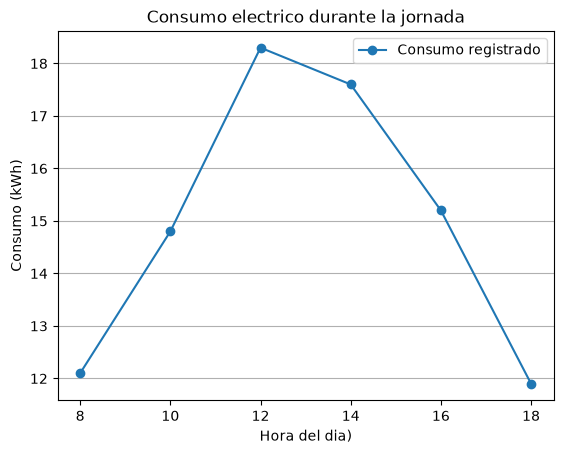

In [ ]:
# Escribe aquí tu solución del ejercicio 31.05.
horas = np.array([8, 10, 12, 14, 16, 18])
consumo_kwh = np.array([12.1, 14.8, 18.3, 17.6, 15.2, 11.9])

fig, ax = plt.subplots()
ax.plot(horas, consumo_kwh, marker = "o", label = "Consumo registrado")
ax.set_title("Consumo electrico durante la jornada")
ax.set_xlabel("Hora del dia")
ax.set_ylabel("Consumo (kWh)")
ax.set_xticks(horas)
ax.grid(axis="y")
ax.legend()
plt.show()

**Lectura del gráfico:** Entre las 8:00 y las 12:00 el consumo eléctrico aumenta de 12,1 kWh hasta alcanzar un máximo de 18,3 kWh, descendiendo después de forma progresiva hasta 11,9 kWh a las 18:00. Aunque este repunte central podría deberse al uso simultáneo de climatización o maquinaria en horas punta, los datos registrados por sí solos no confirman dicha causa.

## Autoevaluación

1. ¿Qué objeto puede contener varios ejes: `Figure` o `Axes`?
2. ¿Por qué una línea no es adecuada para categorías sin orden?
3. ¿Qué información mínima debe aparecer en el eje vertical de una medida física?
4. Si dos series comparten el color, ¿qué otros elementos permiten distinguirlas?
5. Completa: un gráfico muestra un patrón, pero por sí solo no demuestra ________.

**Qué debes saber hacer:** crear y revisar una figura de una línea con etiquetas comprensibles, usar la interfaz `fig, ax` y redactar una lectura prudente de una serie ordenada.